# Assignment 1

## Part I

### 1. Histogram of 25 Most Common Words

In [1]:
# Install NLTK
!pip install nltk

In [2]:
# Install spaCy
!pip install spacy

In [3]:
# Download spaCy en_core_web_sm
!python -m spacy download en_core_web_sm

     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     -------------- ------------------------- 4.7/12.8 MB 25.3 MB/s eta 0:00:01
     ------------------------------- ------- 10.2/12.8 MB 25.4 MB/s eta 0:00:01
     --------------------------------------- 12.8/12.8 MB 23.8 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [4]:
# Download spaCy nl_core_news_sm
!python -m spacy download nl_core_news_sm

     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ------------- -------------------------- 4.5/12.8 MB 24.8 MB/s eta 0:00:01
     ----------------------------- ---------- 9.4/12.8 MB 24.8 MB/s eta 0:00:01
     --------------------------------------- 12.8/12.8 MB 23.5 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('nl_core_news_sm')


In [5]:
# Download spaCy de_core_news_sm
!python -m spacy download de_core_news_sm

     ---------------------------------------- 0.0/14.6 MB ? eta -:--:--
     ------------- -------------------------- 5.0/14.6 MB 25.4 MB/s eta 0:00:01
     --------------------------- ----------- 10.5/14.6 MB 25.3 MB/s eta 0:00:01
     --------------------------------------- 14.6/14.6 MB 24.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('de_core_news_sm')


In [6]:
# Import packages
import nltk, os, re, spacy
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.pyplot import figure
from spacy import displacy
from collections import Counter
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.stem import PorterStemmer, LancasterStemmer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [7]:
# Install punkt tokenizer models
nltk.download('punkt')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\camer\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [8]:
# Path of the texts
path = './data/Part_I_1-2'
# The list of items
files = os.listdir(path)
# Loop to add each file in the Part_I_1-2 folder to the texts list
texts = []
for text in files:
    texts.append(text)

In [9]:
def text_tokens(file):
    """
    Performs sentence splitting and word tokenization.

    Parameter:
        file: TXT file of which the sentences will be split and the words tokenizede.
    Returns:
        List: split sentences containing tokenized words
    """
    # Open the file
    with open(f"./data/Part_I_1-2/{file}", "r") as f:
        # Tokenize the split sentences into words
        return [nltk.word_tokenize(sent) for sent in nltk.sent_tokenize(f.read())]

In [10]:
def text_tokens_amt(words, file):
    """
    Counts the word frequency of word tokens of split sentences in a TXT file.

    Parameters:
        file: TXT file of which the word frequency will be counted.
    Returns:
        Counter: dictionary contains word token, frequency pairs
    """
    # Open the file
    with open(f"./data/Part_I_1-2/{file}", "r") as f:
        # Count the frequency of word tokens of split sentences
        return Counter(word for sublist in words for word in sublist)

In [11]:
# Create the text_token_count dictionary
text_token_count = {}

# Loop over the files in the texts list
for file in texts:
    # Add a key, value pair consisting of the file name and a frequency count of the words
    words = text_tokens(file)
    text_token_count.update({file: text_tokens_amt(words, file)})

In [12]:
# Create the total_token_count Counter()
total_token_count = Counter()
# Loop over the keys in the text_token_count
for key in text_token_count:
    # Add the word frequency count to the total_token_count
    total_token_count += text_token_count[key]

In [13]:
# Add the total_token_count to the text_token_count
text_token_count = dict(text_token_count, total_token_count=total_token_count)

In [85]:
def hist(row, col, file, dictionary):
    """
    Creates a histogram plot of the 25 most common words.

    Parameters:
        row: Current row of the histogram plots.
        col: Current collumns of the histogram plots.
        file: Key of the dictionary.
        dictionary: The dictionary that contains the files.
    Returns:
        Histogram plot.
    """
    # Turns the 25 most common words (values) of a specific key into a dictionary
    word_freq = dict(dictionary[file].most_common(25))
    # Print the top 25 most common words of a specific key in the dictionary
    print(file, word_freq)
    # Turns the words into a list
    words = list(word_freq.keys())
    # Turns the frequency into a list
    freq = list(word_freq.values())

    # Change the file to 'total'
    if (file == 'total_token_count') or (file == 'total_count'):
        file = 'Total'

    # Plot a bar plot
    bar_container = ax[row, col].bar(words, freq)
    ax[row, col].tick_params(axis='x', labelrotation=60)
    ax[row, col].set(ylabel='Frequency', xlabel='Words', title=f'Top 25 Most Common Words in {file}')
    ax[row, col].bar_label(bar_container, fmt='{:,.0f}', rotation=45)

    return ax[row, col]

In [76]:
def histogram(dictionary):
    """
    Creates 6 histograms of the 25 most common words.

    Parameter:
        dictionary: The dictionary that contains the files.
    Returns:
        6 Histograms.
    """
    row = 0
    col = 0
    # Loop over keys in the dictionary
    for file in dictionary:
        # Run the hist(row, col, file, dictionary) function
        hist(row, col, file, dictionary)

        # Check where the histogram is going to be plotted
        if col < 3:
            col += 1
        if (col == 3) and (row == 0):
            col = 0
            row = 1

    plt.tight_layout()
    return plt.show()

01.txt {',': 30, 'the': 14, 'her': 12, 'River': 11, 'Missy': 10, 'a': 10, '.': 10, 'and': 9, 'to': 8, 'was': 7, 'on': 7, '“': 6, '”': 6, 'maps': 5, 'at': 5, '’': 5, 'it': 4, 'over': 4, 's': 4, '?': 3, 'sitting': 3, 'chair': 3, 'had': 3, 'The': 3, 'that': 3}
02.txt {',': 74, 'she': 52, '’': 25, 'the': 20, 'her': 20, '.': 19, 'him': 16, 't': 15, 'and': 14, 'to': 13, 'in': 12, 'She': 12, 'he': 12, 'was': 12, 'a': 11, 'as': 11, 'd': 8, 'had': 8, 'how': 7, 'of': 7, 'back': 6, 'with': 6, 'it': 6, 'who': 5, 'didn': 5}
03.txt {'.': 160, ',': 105, 'the': 64, 'to': 55, 'her': 53, "''": 51, '``': 47, 'and': 47, 'you': 37, 'I': 35, 'he': 32, 'of': 30, 'his': 28, 'was': 27, 'Rose': 25, 'a': 24, 'He': 24, 'it': 24, "'": 24, "'d": 21, 'Doctor': 20, 'she': 20, 'that': 18, 'in': 18, 'She': 18}
04.txt {'.': 89, 'to': 50, ',': 42, 'the': 41, 'The': 38, 'was': 30, 'Doctor': 30, 'he': 26, '’': 24, 'her': 22, 'and': 22, 'that': 21, 'Rose': 21, 'Martha': 20, 'she': 18, 'a': 17, 'of': 16, 'He': 16, 'had': 14,

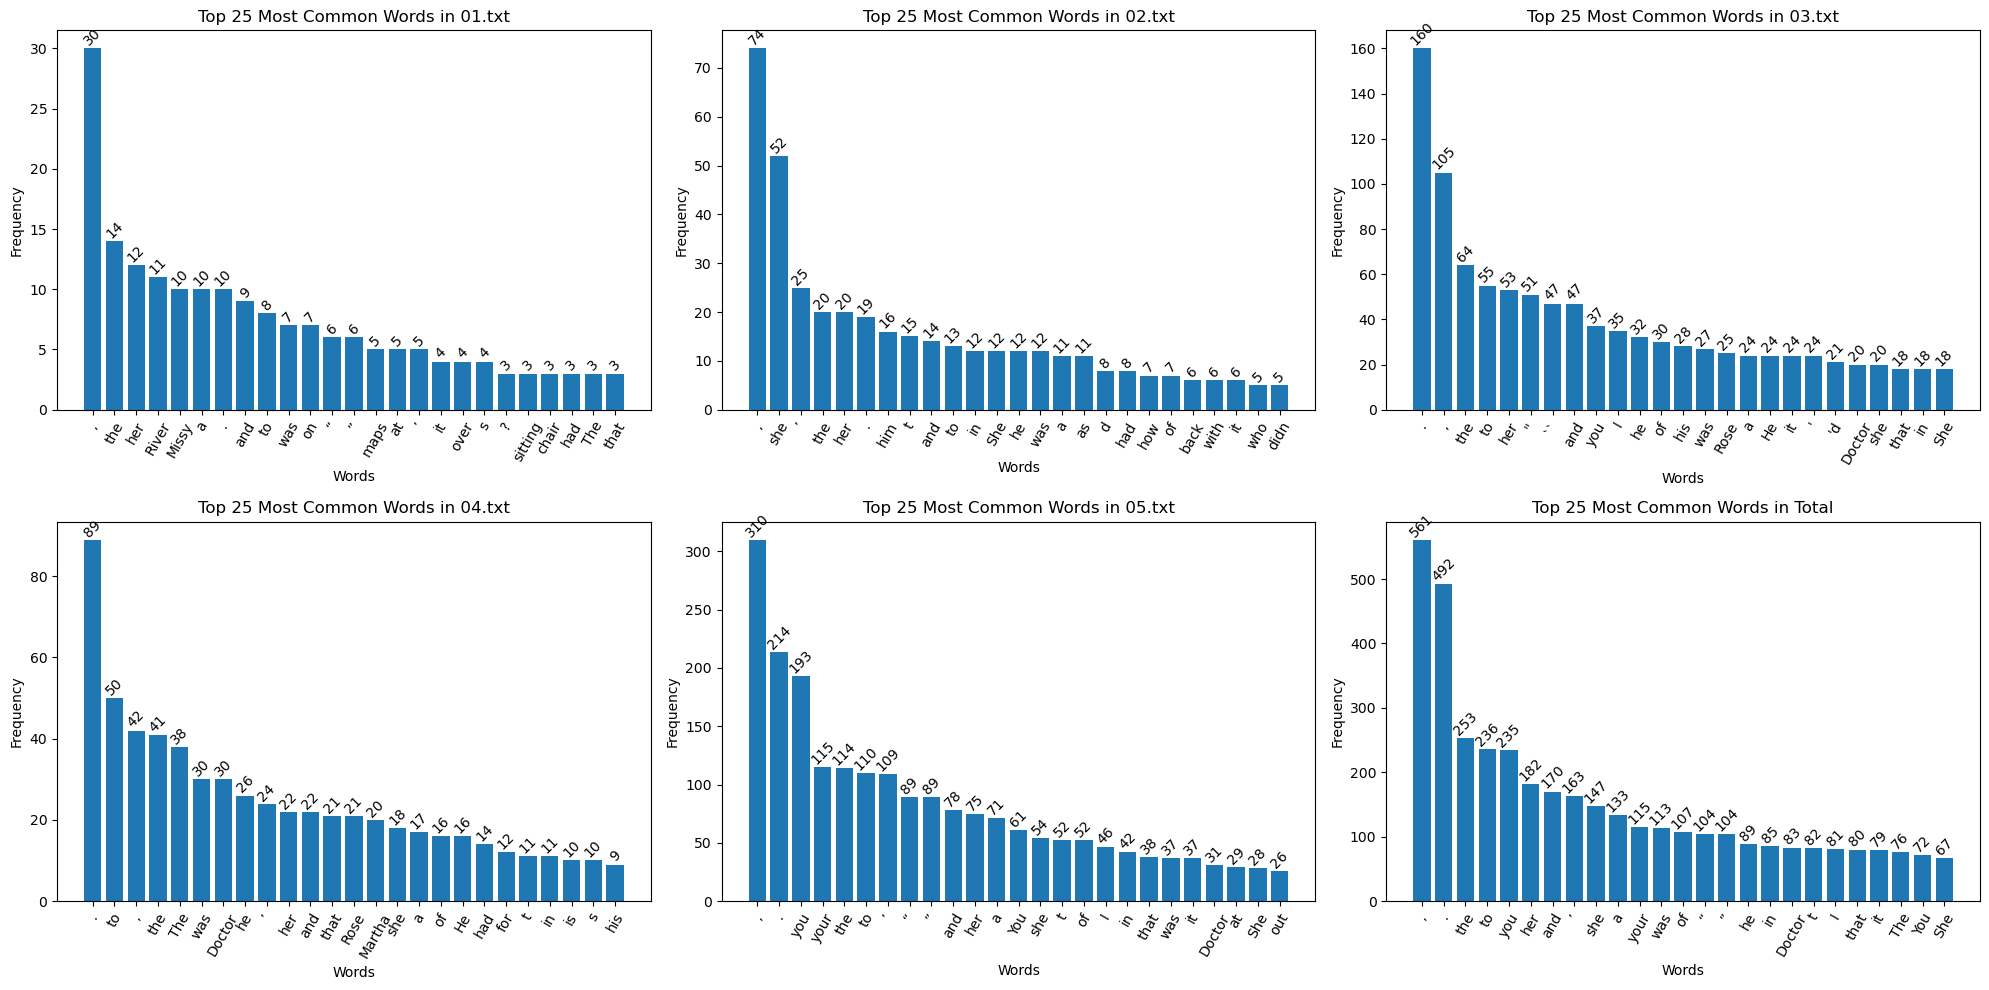

In [86]:
# Plot a histogram plot
fig, ax = plt.subplots(2, 3, figsize=(20, 10))
histogram(text_token_count)

### 2. Histogram of 25 Most Common Words with Stemmed Texts

In [17]:
porter = PorterStemmer()
lancaster = LancasterStemmer()

In [18]:
# Create the tokens dictionary
tokens = {}

# Loop over the files in the texts list
for file in texts:
    # Add a key, value pair consisting of the file name and split sentences of tokenized words words
    tokens.update({file: text_tokens(file)})
    # Turn the list of lists into a single list
    tokens[file] = [word for sublist in tokens[file] for word in sublist]

In [19]:
# Create dictionaries
porter_words = {}
lancaster_words = {}

# Loop over the keys in the tokens dictionary
for key in tokens:
    # Add a key, value pair consisting of the key name and Porter stemmed words
    porter_words.update({key: [porter.stem(word) for word in tokens[key]]})
    # Add a key, value pair consisting of the key name and Lancaster stemmed words
    lancaster_words.update({key: [lancaster.stem(word) for word in tokens[key]]})

In [20]:
def stemmed_count(dictionary):
    """
    Creates dictionary of word counts.

    Parameter:
        dictionary: The dictionary that contains the words to be counted.
    Returns:
        dict: contains the words with the frequency of occurence.
    """
    # Create dictionaries
    token_count = {}
    # Loop over the files in the texts list
    for file in texts:
        # Add a key, value pair consisting of the file name and a frequency count of the words
        token_count.update({file: Counter(dictionary[file])})
    # Create the Counters
    total_count = Counter()
    # Loop over the keys in the token_count
    for key in token_count:
        # Add the word frequency count to the total_count
        total_count += token_count[key]
    # Add the total_count to the token_count
    token_count = dict(token_count, total_count=total_count)

    return token_count

01.txt {',': 30, 'the': 17, 'her': 12, 'river': 11, 'missi': 10, 'a': 10, '.': 10, 'and': 9, 'to': 8, 'wa': 7, 'on': 7, 'map': 7, 'it': 6, '“': 6, '”': 6, 'smile': 6, 'she': 5, 'look': 5, 'at': 5, '’': 5, 'place': 5, 'that': 4, 'over': 4, 's': 4, '?': 3}
02.txt {',': 74, 'she': 64, '’': 25, 'her': 21, 'the': 20, '.': 19, 'him': 16, 't': 15, 'and': 14, 'to': 13, 'he': 13, 'in': 12, 'wa': 12, 'a': 11, 'as': 11, 'd': 8, 'how': 8, 'had': 8, 'it': 8, 'want': 7, 'of': 7, 'look': 6, 'back': 6, 'with': 6, 'you': 5}
03.txt {'.': 160, ',': 105, 'the': 80, 'her': 57, 'he': 56, 'to': 55, "''": 51, 'you': 47, '``': 47, 'and': 47, 'she': 38, 'i': 35, 'of': 32, 'it': 31, 'hi': 30, 'wa': 27, 'rose': 25, 'a': 24, "'": 24, "'d": 21, 'doctor': 20, 'but': 19, 'not': 19, 'that': 18, 'in': 18}
04.txt {'.': 89, 'the': 79, 'to': 50, ',': 42, 'he': 42, 'wa': 30, 'doctor': 30, 'she': 25, 'her': 24, '’': 24, 'rose': 22, 'that': 22, 'and': 22, 'martha': 20, 'a': 17, 'of': 16, 'had': 14, 'for': 12, 'hi': 11, 't': 

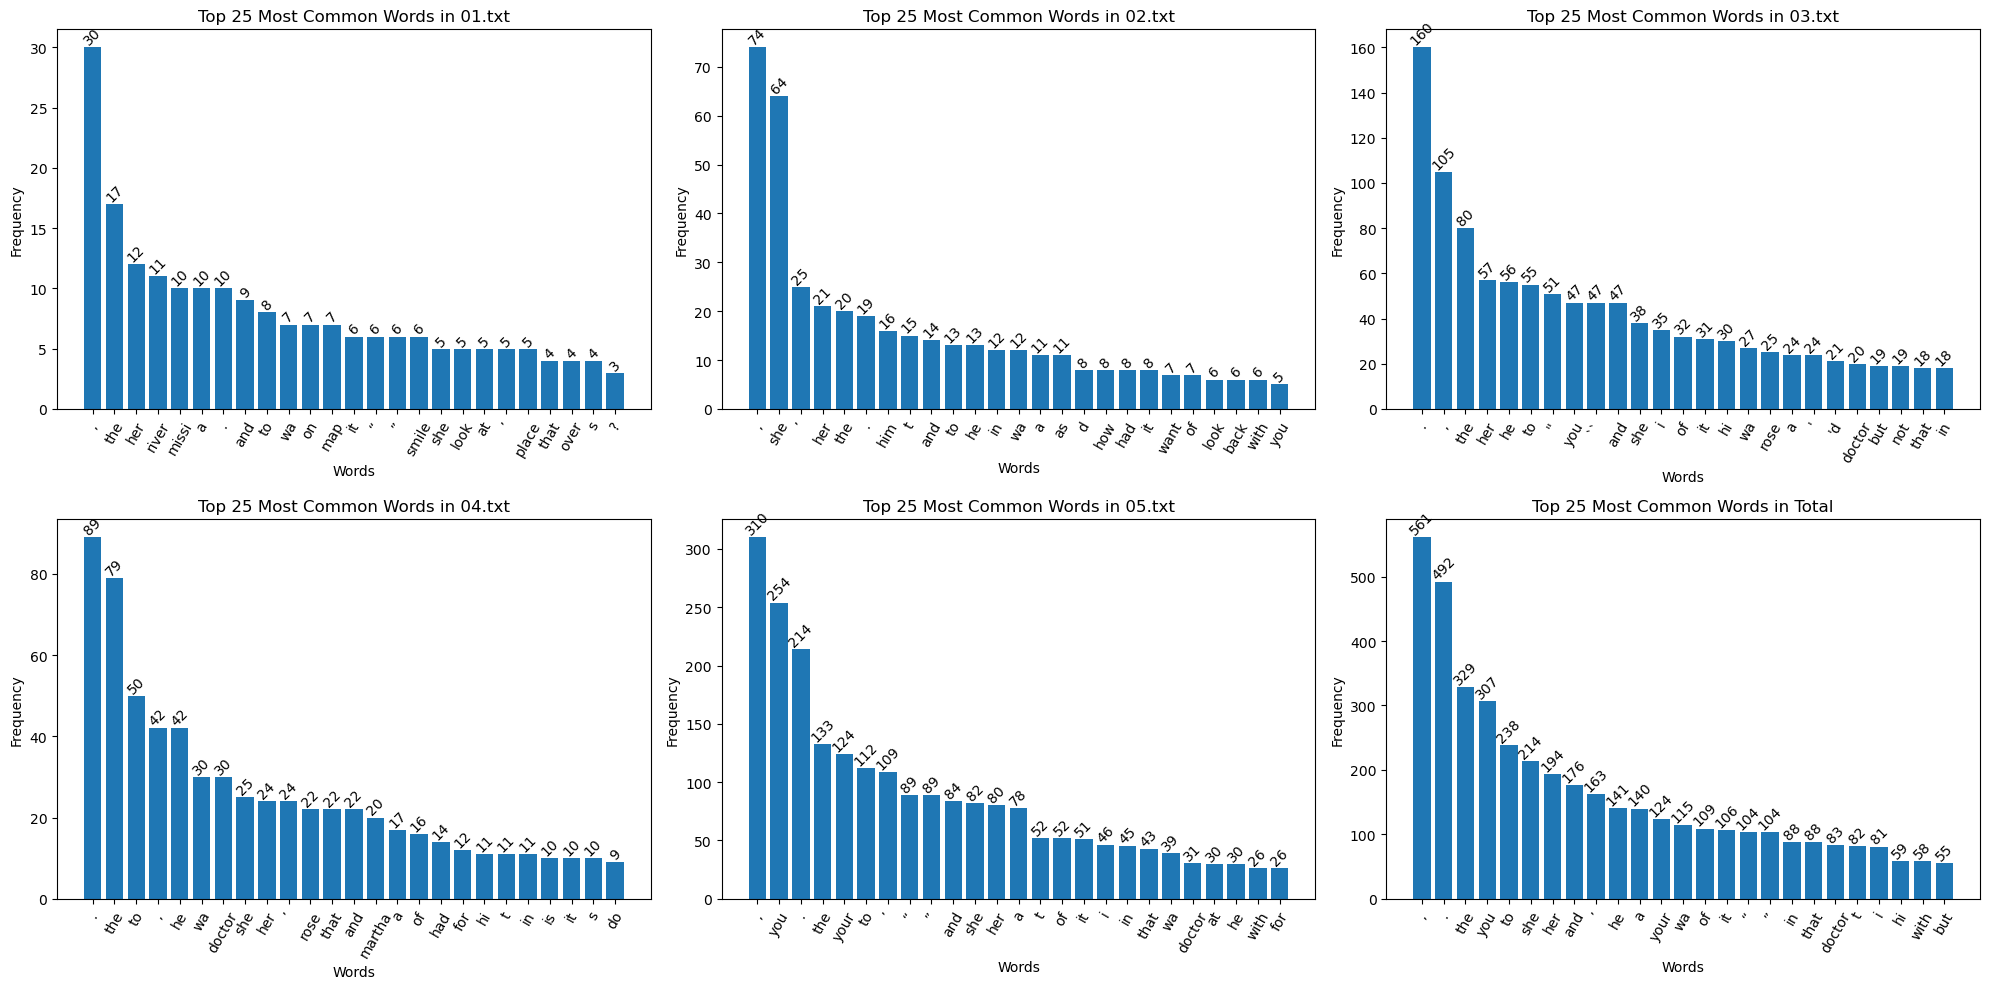

In [87]:
# Plot a histogram plot
fig, ax = plt.subplots(2, 3, figsize=(20, 10))
histogram(stemmed_count(porter_words))

01.txt {',': 30, 'the': 17, 'her': 12, 'riv': 11, 'missy': 10, 'a': 10, '.': 10, 'and': 9, 'to': 8, 'was': 7, 'on': 7, 'map': 7, 'it': 6, '“': 6, '”': 6, 'smil': 6, 'she': 5, 'look': 5, 'at': 5, '’': 5, 'plac': 5, 'that': 4, 'ov': 4, 's': 4, '?': 3}
02.txt {',': 74, 'she': 64, '’': 25, 'her': 23, 'the': 20, '.': 19, 'him': 16, 't': 15, 'and': 14, 'to': 13, 'he': 13, 'in': 12, 'was': 12, 'a': 11, 'as': 11, 'd': 8, 'how': 8, 'had': 8, 'it': 8, 'want': 7, 'on': 7, 'of': 7, 'look': 6, 'back': 6, 'with': 6}
03.txt {'.': 160, ',': 105, 'the': 80, 'her': 57, 'he': 56, 'to': 55, "''": 51, 'you': 47, '``': 47, 'and': 47, 'she': 38, 'i': 35, 'of': 32, 'it': 31, 'his': 30, 'was': 27, 'ros': 25, 'a': 24, "'": 24, "'d": 21, 'doct': 20, 'on': 20, 'but': 19, 'not': 19, 'that': 18}
04.txt {'.': 89, 'the': 79, 'to': 50, ',': 42, 'he': 42, 'was': 30, 'doct': 30, 'she': 25, 'her': 25, '’': 24, 'ros': 22, 'that': 22, 'and': 22, 'marth': 20, 'a': 17, 'of': 16, 'had': 14, 'for': 12, 'his': 11, 't': 11, 'in'

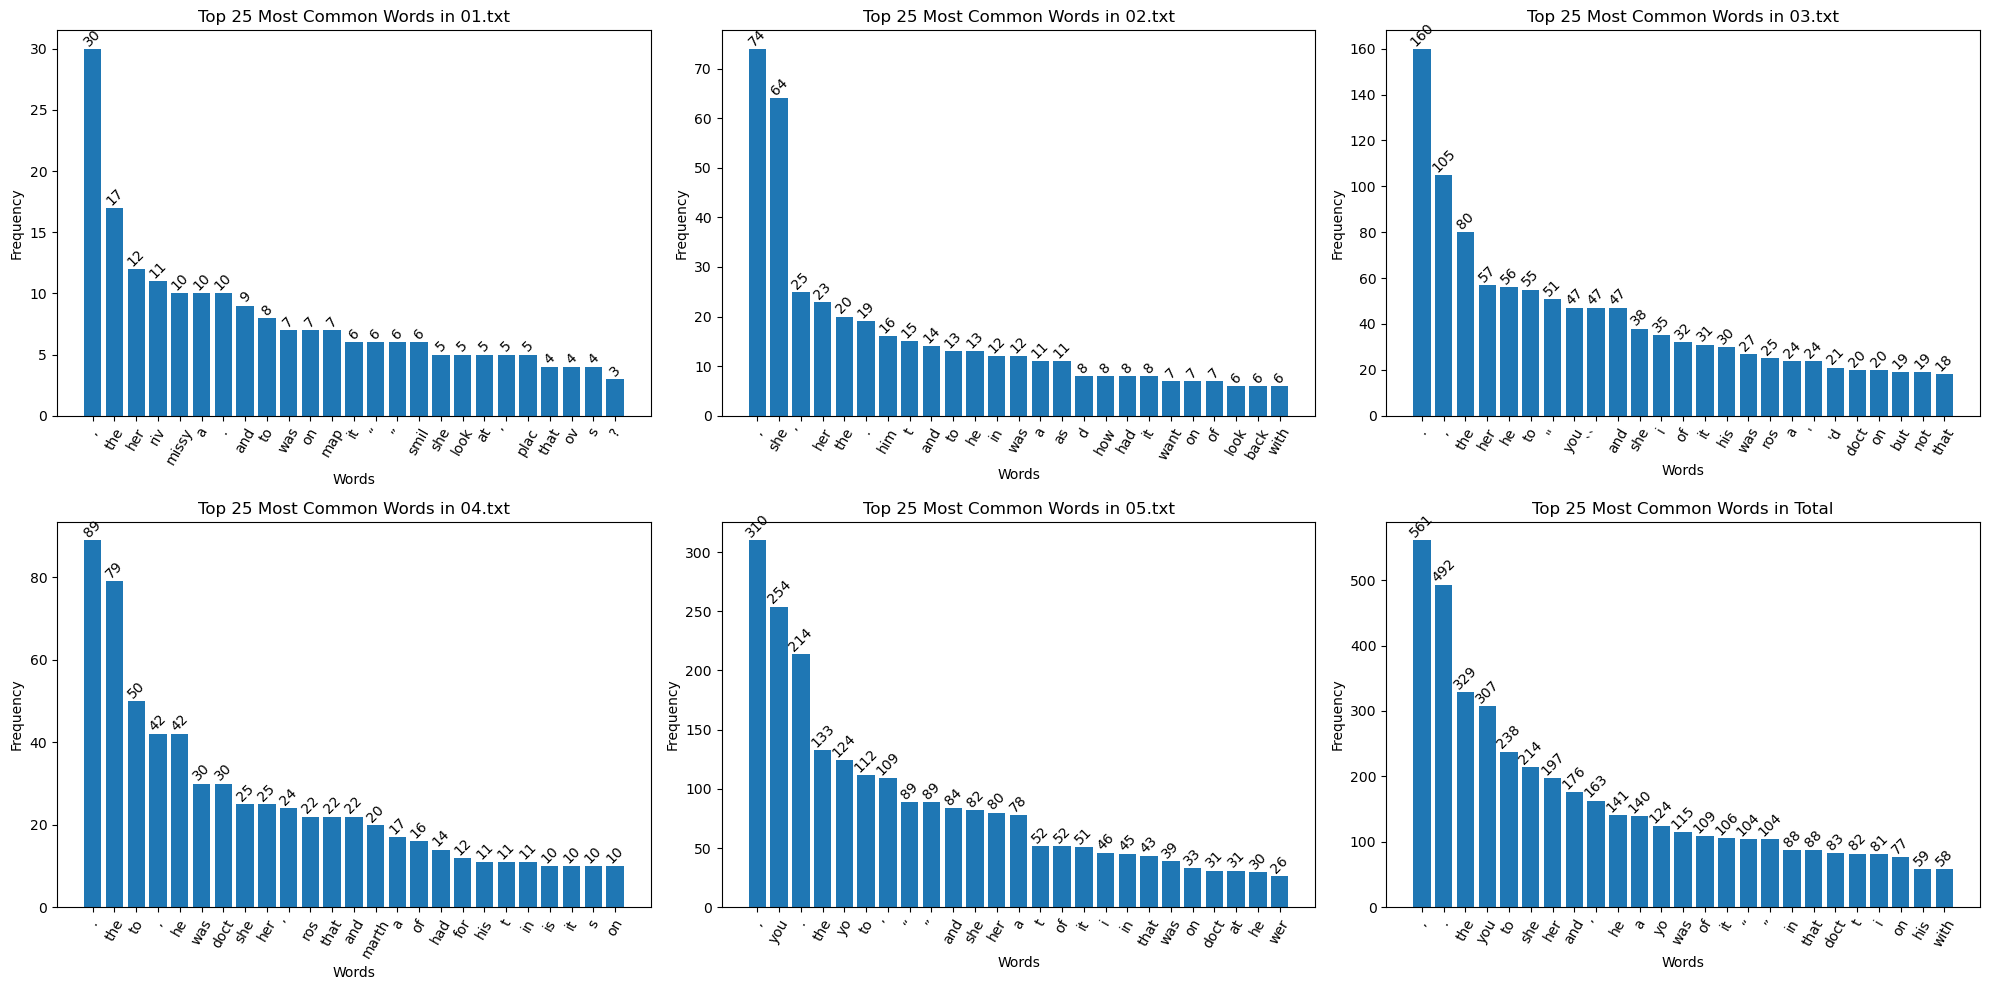

In [88]:
# Plot a histogram plot
fig, ax = plt.subplots(2, 3, figsize=(20, 10))
histogram(stemmed_count(lancaster_words))

### 3. POS-tags with spaCy

In [23]:
# Read the files in Part_I_3
with open("./data/Part_I_3/pg74.txt", "r") as text_english:
    en_text = text_english.read()
with open("./data/Part_I_3/pg18381.txt", "r") as text_dutch:
    nl_text = text_dutch.read()
with open("./data/Part_I_3/pg30165.txt", "r") as text_german:
    de_text = text_german.read()

In [24]:
# Clean the texts
clean_en = re.search(r'(CHAPTER I\n)[\s\S]+', en_text).group()
cleaned_en = re.sub(r'(\n{7}\*{3} END OF THE PROJECT GUTENBERG EBOOK THE ADVENTURES OF TOM SAWYER, COMPLETE \*{3})[\s\S]+', "", clean_en)

clean_nl = re.search(r'(HOOFDSTUK I.\n)[\s\S]+', nl_text).group()
cleaned_nl = re.sub(r"(\n{7}End of Project Gutenberg's De Lotgevallen van Tom Sawyer, by Mark Twain)[\s\S]+", "", clean_nl)

clean_de = re.search(r'(Erstes Kapitel.\n)[\s\S]+', de_text).group()
cleaned_de = re.sub(r'(\n{7}\s{8}\n\s{12}\*{3} END OF THE PROJECT GUTENBERG EBOOK DIE ABENTEUER TOM SAWYERS \*{3})[\s\S]+', "", clean_de)

In [25]:
# Load trained English, Dutch, and German pipelines
nlp_en = spacy.load("en_core_web_sm")
nlp_nl = spacy.load("nl_core_news_sm")
nlp_de = spacy.load("de_core_news_sm")

In [26]:
# Process the texts
doc_en = nlp_en(cleaned_en)
doc_nl = nlp_nl(cleaned_nl)
doc_de = nlp_de(cleaned_de)

In [27]:
def count_pos(doc):
    """
    Adds Parts-of-Speech tags.

    Parameter:
        doc: Contains the text with the POS-tags.
    Returns:
        dict: reverse sorted by values.
    """
    # Create dictionary
    doc_dict = {}
    # Loop over the tokens in the doc
    for token in doc:
        # Check if the token.pos_ key exists in the doc_dict dictionary
        if token.pos_ not in doc_dict:
            # Add the token.pos_ key to the doc_dict dictionary
            doc_dict[token.pos_] = 0
        # Increase the token.pos_ count with 1
        doc_dict[token.pos_] += 1
    
    return dict(sorted(doc_dict.items(), key=lambda item: item[1], reverse=True))

In [28]:
# Create dictionaries of POS-tag counts
doc_en_dict = count_pos(doc_en)
doc_nl_dict = count_pos(doc_nl)
doc_de_dict = count_pos(doc_de)

print(doc_en_dict)
print(doc_nl_dict)
print(doc_de_dict)

{'PUNCT': 15310, 'NOUN': 12144, 'VERB': 11292, 'PRON': 10268, 'ADP': 7258, 'DET': 6856, 'SPACE': 6393, 'ADV': 4883, 'ADJ': 4404, 'AUX': 4377, 'CCONJ': 3840, 'PROPN': 3010, 'PART': 2085, 'SCONJ': 1805, 'NUM': 639, 'INTJ': 475, 'X': 73, 'SYM': 1}
{'PUNCT': 13946, 'NOUN': 11919, 'VERB': 11768, 'PRON': 10021, 'ADP': 8792, 'SPACE': 7215, 'DET': 7113, 'ADV': 5761, 'ADJ': 5048, 'AUX': 3839, 'CCONJ': 3502, 'PROPN': 3467, 'SCONJ': 1999, 'NUM': 391, 'INTJ': 365, 'SYM': 352, 'X': 23}
{'PUNCT': 18397, 'NOUN': 11099, 'VERB': 9468, 'ADV': 9266, 'PRON': 8771, 'DET': 7449, 'SPACE': 6630, 'ADP': 5268, 'AUX': 3740, 'CCONJ': 3356, 'ADJ': 2914, 'PROPN': 2181, 'PART': 1679, 'SCONJ': 1514, 'NUM': 309, 'X': 221, 'INTJ': 208}


## Part II

In [29]:
def named_entity_rec(file):
    """
    Performs Named Entity Recognition.

    Parameter:
        file: TXT file on which the Named Entity Recognition will be performed.
    Returns:
        displacy: Named Entity Recognition visual
    """
    # Open the file
    with open(f"./data/Part_I_1-2/{file}", "r") as f:
        # Process the text
        doc = nlp_en(f.read())
        print(file)
        # Document level
        df_ner = pd.DataFrame([(ent.text, ent.start_char, ent.end_char, ent.label_) for ent in doc.ents], columns=['text', 'start_char', 'end_char', 'ner'])
        print(df_ner)
        
        return displacy.render(doc, style="ent", jupyter=True)

In [30]:
# Loop over the files in the texts list
for file in texts:
    named_entity_rec(file)

01.txt
            text  start_char  end_char      ner
0          Missy          32        37   PERSON
1          River         142       147      LOC
2          Missy         405       410   PERSON
3   Mary Poppins         432       444   PERSON
4          River         461       466      LOC
5          River         644       649  PRODUCT
6          River         678       683      LOC
7          Missy         776       781   PERSON
8          Missy         833       838   PERSON
9          Missy         904       909      ORG
10         River         928       933      ORG
11         Missy        1003      1008      ORG
12         River        1062      1067      LOC
13       an hour        1144      1151     TIME
14         Missy        1201      1206   PERSON
15         River        1238      1243      LOC
16         Missy        1337      1342   PERSON
17         River        1419      1424      ORG
18         Missy        1433      1438   PERSON
19         River        1522     

02.txt
           text  start_char  end_char       ner
0     these day         477       486      DATE
1       one day         643       650      DATE
2   a few years         746       757      DATE
3          1969        1048      1052      DATE
4      New York        1097      1105       GPE
5         three        1237      1242  CARDINAL
6        second        1519      1525   ORDINAL
7    an hour or        1948      1958      TIME
8           one        2275      2278  CARDINAL
9         three        2286      2291  CARDINAL
10        River        2326      2331       ORG
11          n’t        2520      2523       GPE
12  another day        3253      3264      DATE


03.txt
                  text  start_char  end_char          ner
0           Rose Tyler         258       268       PERSON
1            My Doctor         327       336  WORK_OF_ART
2                 Rose         370       374       PERSON
3                  one         668       671     CARDINAL
4           Rose Tyler         864       874       PERSON
5                  Two        1117      1120     CARDINAL
6                  two        1148      1151     CARDINAL
7                  two        1212      1215     CARDINAL
8           Rose Tyler        1438      1448       PERSON
9            Barcelona        1535      1544          GPE
10           Barcelona        1559      1568          GPE
11           Barcelona        1581      1590          GPE
12              tellin        1696      1702       PERSON
13                Rose        1822      1826       PERSON
14             Reapers        1944      1951          ORG
15                Rose        2057      2061       PERSON
16     

04.txt
            text  start_char  end_char       ner
0           Rose         405       409    PERSON
1   the Time War         667       679     EVENT
2           Rose         764       768    PERSON
3           Rose        1159      1163    PERSON
4          Donna        1193      1198    PERSON
5         TARDIS        1215      1221       ORG
6         Martha        1394      1400    PERSON
7           Rose        1703      1707    PERSON
8         TARDIS        1727      1733       ORG
9    Gallifreyan        1760      1771    PERSON
10   Gallifreyan        1870      1881   PRODUCT
11       English        1885      1892  LANGUAGE
12          Rose        1971      1975    PERSON
13        TARDIS        2068      2074       ORG
14     Gallifrey        2182      2191    PERSON
15        TARDIS        2200      2206       ORG
16        TARDIS        2265      2271       ORG
17          Rose        2501      2505    PERSON
18          Rose        2650      2654    PERSON
19         Te

05.txt
                  text  start_char  end_char          ner
0                  two         518       521     CARDINAL
1                first         767       772      ORDINAL
2                  one         933       936     CARDINAL
3                  two        1054      1057     CARDINAL
4                  two        1894      1897     CARDINAL
5               TARDIS        2050      2056          ORG
6              the day        3375      3382         DATE
7             Universe        4081      4089       PERSON
8                  Y/n        5677      5680  WORK_OF_ART
9               TARDIS        5846      5852          ORG
10               first        5876      5881      ORDINAL
11            Universe        6719      6727          ORG
12                Days        6734      6738         DATE
13               weeks        6751      6756         DATE
14               third        7608      7613      ORDINAL
15   a few months back        7794      7811         DATE
16  Tor

In [31]:
def NER_BIO_sequence_model(text):
    """
    Performs Named Entity Recognition using the BIO sequence model.

    Parameter:
        text: string on which Named Entity Recognition will be performed.
    Returns:
        result: List which contains a token followed by its BIO sequence model tag and the Named Entity Recognition label.
    """
    # Process the text
    doc = nlp_en(text)
    # Token level
    token_count = 0
    result = []
    # Loop over the tokens in the doc
    for token in doc:
        # Check if the BIO sequence model tag is equal to 'O'
        if doc[token_count].ent_iob_ == 'O':
            # Add the token and the BIO sequence model tag to the result list
            result += [doc[token_count].text, doc[token_count].ent_iob_]
        else:
            # Add the token, BIO sequence model tag, and the NER label to the list 
            result += [doc[token_count].text, doc[token_count].ent_iob_ + '-' + doc[token_count].ent_type_]
        token_count += 1
    
    return result

In [32]:
def keep_only_bio(specific_list):
    """
    Keeps only the BIO sequence model tag and the Named Entity Recognition.

    Parameter:
        list: contains a token followed by its BIO sequence model tag.
    Returns:
        result: List which contains a word followed by its BIO sequence model tag and the Named Entity Recognition label.
    """
    # Loop over list
    for token in specific_list:
        # Check if the token does not start with 'B-' or 'I-' or is equal to 'O'
        if not (token.startswith('B-')) or (token.startswith("I-")) or token == 'O':
            # Remove the token
            specific_list.remove(token)
    
    return specific_list

In [33]:
def performance_measure(y_true, y_pred):
    """
    Calculates the performance measure.

    Parameter:
        y_true: True Named Entity Recognition labels.
        y_pred: Predicted Named Entity Recognition labels.
    Returns:
        Classification report.
    """
    # Plot a confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot()
    plt.show()

    # Print the performance measures
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("F1 macro:", f1_score(y_true, y_pred, average="macro"))
    print("F1 micro:", f1_score(y_true, y_pred, average="micro"))
    print("F1 weighted:", f1_score(y_true, y_pred, average="weighted"))

    print("Detailed report:")
    return print(classification_report(y_true, y_pred, zero_division=0))

In [34]:
# Assign the sentence to perform NER and BIO sequence modelling on to the text_01 variable
text_01 = "Missy smiles and leans back, placing a kiss on River's jaw, a smile on her face, River reaches onto the table for a cup of coffee, gracefully sitting herself on the chair next to Missy, she raises the cups to her lips, wondering wether Missy had noticed yet."
# Run the NER_BIO_sequence_model(text) function
spacy_01 = NER_BIO_sequence_model(text_01)
print(spacy_01)

['Missy', 'O', 'smiles', 'O', 'and', 'O', 'leans', 'O', 'back', 'O', ',', 'O', 'placing', 'O', 'a', 'O', 'kiss', 'O', 'on', 'O', 'River', 'B-LOC', "'s", 'O', 'jaw', 'O', ',', 'O', 'a', 'O', 'smile', 'O', 'on', 'O', 'her', 'O', 'face', 'O', ',', 'O', 'River', 'B-LOC', 'reaches', 'O', 'onto', 'O', 'the', 'O', 'table', 'O', 'for', 'O', 'a', 'O', 'cup', 'O', 'of', 'O', 'coffee', 'O', ',', 'O', 'gracefully', 'O', 'sitting', 'O', 'herself', 'O', 'on', 'O', 'the', 'O', 'chair', 'O', 'next', 'O', 'to', 'O', 'Missy', 'B-PERSON', ',', 'O', 'she', 'O', 'raises', 'O', 'the', 'O', 'cups', 'O', 'to', 'O', 'her', 'O', 'lips', 'O', ',', 'O', 'wondering', 'O', 'wether', 'O', 'Missy', 'B-PERSON', 'had', 'O', 'noticed', 'O', 'yet', 'O', '.', 'O']


['B-PERSON', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-PERSON', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-PERSON', 'O', 'O', 'O', 'B-PRODUCT', 'O', 'B-PRODUCT', 'I-PRODUCT', 'I-PRODUCT', 'I-PRODUCT', 'O', 'O', 'O', 'O', 'O', 'O', 'B-PRODUCT', 'O', 'O', 'B-PERSON', 'O', 'O', 'O', 'O', 'B-PRODUCT', 'O', 'O', 'O', 'O', 'O', 'O', 'B-PERSON', 'O', 'O', 'O', 'O']
['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-LOC', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-LOC', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-PERSON', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-PERSON', 'O', 'O', 'O', 'O']


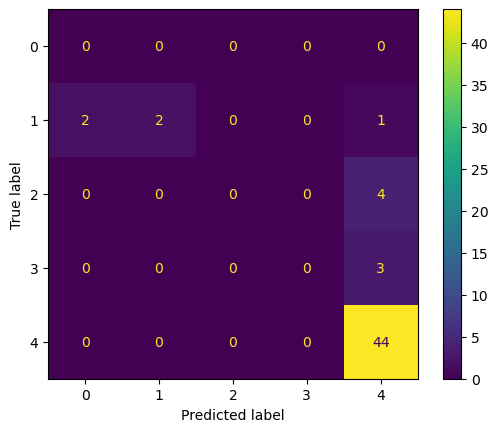

Accuracy: 0.8214285714285714
F1 macro: 0.2976190476190476
F1 micro: 0.8214285714285714
F1 weighted: 0.7712585034013604
Detailed report:
              precision    recall  f1-score   support

       B-LOC       0.00      0.00      0.00         0
    B-PERSON       1.00      0.40      0.57         5
   B-PRODUCT       0.00      0.00      0.00         4
   I-PRODUCT       0.00      0.00      0.00         3
           O       0.85      1.00      0.92        44

    accuracy                           0.82        56
   macro avg       0.37      0.28      0.30        56
weighted avg       0.75      0.82      0.77        56



In [35]:
# Manually perform Named Entity Recognition and BIO sequence modelling on the text_01 variable
manual_01 = ['Missy', 'B-PERSON', 'smiles', 'O', 'and', 'O', 'leans', 'O', 'back', 'O', ',', 'O', 'placing', 'O', 'a', 'O', 'kiss', 'O', 'on', 'O', 'River', 'B-PERSON', "'s", 'O', 'jaw', 'O', ',', 'O', 'a', 'O', 'smile', 'O', 'on', 'O', 'her', 'O', 'face', 'O', ',', 'O', 'River', 'B-PERSON', 'reaches', 'O', 'onto', 'O', 'the', 'O', 'table', 'B-PRODUCT', 'for', 'O', 'a', 'B-PRODUCT', 'cup', 'I-PRODUCT', 'of', 'I-PRODUCT', 'coffee', 'I-PRODUCT', ',', 'O', 'gracefully', 'O', 'sitting', 'O', 'herself', 'O', 'on', 'O', 'the', 'O', 'chair', 'B-PRODUCT', 'next', 'O', 'to', 'O', 'Missy', 'B-PERSON', ',', 'O', 'she', 'O', 'raises', 'O', 'the', 'O', 'cups', 'B-PRODUCT', 'to', 'O', 'her', 'O', 'lips', 'O', ',', 'O', 'wondering', 'O', 'wether', 'O', 'Missy', 'B-PERSON', 'had', 'O', 'noticed', 'O', 'yet', 'O', '.', 'O']

# Run the keep_only_bio(specific_list) function
y_true_01 = keep_only_bio(manual_01)
y_pred_01 = keep_only_bio(spacy_01)

print(y_true_01)
print(y_pred_01)

# Run the performance_measure(y_true, y_pred) function
performance_measure(y_true_01, y_pred_01)

In [36]:
# Assign the sentence to perform NER and BIO sequence modelling on to the text_02 variable
text_02 = "She wished it could have been him after he knew who she was, because what he was mostly talking about was 1969, she wanted to know how her parents were in New York, she wanted the more mature version of him, but she lent against him, sitting in the garden, gently pulling him up to show him the three children she had been left with, it wasn't night yet and they were playing together."
# Run the NER_BIO_sequence_model(text) function
spacy_02 = NER_BIO_sequence_model(text_02)
print(spacy_02)

['She', 'O', 'wished', 'O', 'it', 'O', 'could', 'O', 'have', 'O', 'been', 'O', 'him', 'O', 'after', 'O', 'he', 'O', 'knew', 'O', 'who', 'O', 'she', 'O', 'was', 'O', ',', 'O', 'because', 'O', 'what', 'O', 'he', 'O', 'was', 'O', 'mostly', 'O', 'talking', 'O', 'about', 'O', 'was', 'O', '1969', 'B-DATE', ',', 'O', 'she', 'O', 'wanted', 'O', 'to', 'O', 'know', 'O', 'how', 'O', 'her', 'O', 'parents', 'O', 'were', 'O', 'in', 'O', 'New', 'B-GPE', 'York', 'I-GPE', ',', 'O', 'she', 'O', 'wanted', 'O', 'the', 'O', 'more', 'O', 'mature', 'O', 'version', 'O', 'of', 'O', 'him', 'O', ',', 'O', 'but', 'O', 'she', 'O', 'lent', 'O', 'against', 'O', 'him', 'O', ',', 'O', 'sitting', 'O', 'in', 'O', 'the', 'O', 'garden', 'O', ',', 'O', 'gently', 'O', 'pulling', 'O', 'him', 'O', 'up', 'O', 'to', 'O', 'show', 'O', 'him', 'O', 'the', 'O', 'three', 'B-CARDINAL', 'children', 'O', 'she', 'O', 'had', 'O', 'been', 'O', 'left', 'O', 'with', 'O', ',', 'O', 'it', 'O', 'was', 'O', "n't", 'O', 'night', 'O', 'yet', 'O',

['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-DATE', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-PERSON', 'O', 'O', 'B-GPE', 'I-GPE', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-CARDINAL', 'B-PERSON', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-TIME', 'O', 'O', 'O', 'O', 'O', 'O', 'O']
['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-DATE', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-GPE', 'I-GPE', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-CARDINAL', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']


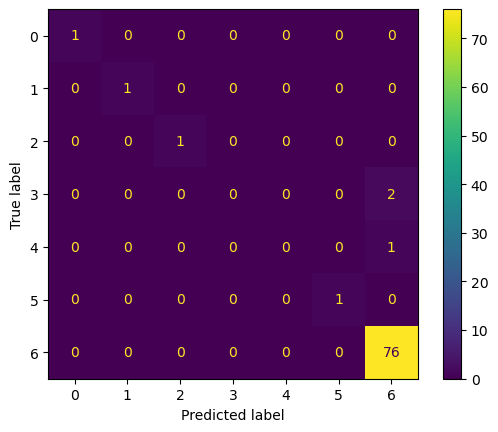

Accuracy: 0.963855421686747
F1 macro: 0.7115207373271889
F1 micro: 0.963855421686747
F1 weighted: 0.9461329187718617
Detailed report:
              precision    recall  f1-score   support

  B-CARDINAL       1.00      1.00      1.00         1
      B-DATE       1.00      1.00      1.00         1
       B-GPE       1.00      1.00      1.00         1
    B-PERSON       0.00      0.00      0.00         2
      B-TIME       0.00      0.00      0.00         1
       I-GPE       1.00      1.00      1.00         1
           O       0.96      1.00      0.98        76

    accuracy                           0.96        83
   macro avg       0.71      0.71      0.71        83
weighted avg       0.93      0.96      0.95        83



In [37]:
# Manually perform Named Entity Recognition and BIO sequence modelling on the text_02 variable
manual_02 = ['She', 'O', 'wished', 'O', 'it', 'O', 'could', 'O', 'have', 'O', 'been', 'O', 'him', 'O', 'after', 'O', 'he', 'O', 'knew', 'O', 'who', 'O', 'she', 'O', 'was', 'O', ',', 'O', 'because', 'O', 'what', 'O', 'he', 'O', 'was', 'O', 'mostly', 'O', 'talking', 'O', 'about', 'O', 'was', 'O', '1969', 'B-DATE', ',', 'O', 'she', 'O', 'wanted', 'O', 'to', 'O', 'know', 'O', 'how', 'O', 'her', 'O', 'parents', 'B-PERSON', 'were', 'O', 'in', 'O', 'New', 'B-GPE', 'York', 'I-GPE', ',', 'O', 'she', 'O', 'wanted', 'O', 'the', 'O', 'more', 'O', 'mature', 'O', 'version', 'O', 'of', 'O', 'him', 'O', ',', 'O', 'but', 'O', 'she', 'O', 'lent', 'O', 'against', 'O', 'him', 'O', ',', 'O', 'sitting', 'O', 'in', 'O', 'the', 'O', 'garden', 'O', ',', 'O', 'gently', 'O', 'pulling', 'O', 'him', 'O', 'up', 'O', 'to', 'O', 'show', 'O', 'him', 'O', 'the', 'O', 'three', 'B-CARDINAL', 'children', 'B-PERSON', 'she', 'O', 'had', 'O', 'been', 'O', 'left', 'O', 'with', 'O', ',', 'O', 'it', 'O', 'was', 'O', "n't", 'O', 'night', 'B-TIME', 'yet', 'O', 'and', 'O', 'they', 'O', 'were', 'O', 'playing', 'O', 'together', 'O', '.', 'O']

# Run the keep_only_bio(specific_list) function
y_true_02 = keep_only_bio(manual_02)
y_pred_02 = keep_only_bio(spacy_02)

print(y_true_02)
print(y_pred_02)

# Run the performance_measure(y_true, y_pred) function
performance_measure(y_true_02, y_pred_02)

In [38]:
# Assign the sentence to perform NER and BIO sequence modelling on to the text_03 variable
text_03 = "It was then the Doctor understood- the small part of his brain not occupied with kissing Rose calculated what the Bad Wolf had already known. The vortex energy was bonding with the regenerative energy, and dividing both between the two of them."
# Run the NER_BIO_sequence_model(text) function
spacy_03 = NER_BIO_sequence_model(text_03)
print(spacy_03)

['It', 'O', 'was', 'O', 'then', 'O', 'the', 'O', 'Doctor', 'O', 'understood-', 'O', 'the', 'O', 'small', 'O', 'part', 'O', 'of', 'O', 'his', 'O', 'brain', 'O', 'not', 'O', 'occupied', 'O', 'with', 'O', 'kissing', 'O', 'Rose', 'B-PERSON', 'calculated', 'O', 'what', 'O', 'the', 'B-PERSON', 'Bad', 'I-PERSON', 'Wolf', 'I-PERSON', 'had', 'O', 'already', 'O', 'known', 'O', '.', 'O', 'The', 'O', 'vortex', 'O', 'energy', 'O', 'was', 'O', 'bonding', 'O', 'with', 'O', 'the', 'O', 'regenerative', 'O', 'energy', 'O', ',', 'O', 'and', 'O', 'dividing', 'O', 'both', 'O', 'between', 'O', 'the', 'O', 'two', 'B-CARDINAL', 'of', 'O', 'them', 'O', '.', 'O']


['O', 'O', 'O', 'B-PERSON', 'I-PERSON', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-PERSON', 'O', 'O', 'O', 'B-PERSON', 'I-PERSON', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-CARDINAL', 'O', 'O', 'O']
['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-PERSON', 'O', 'O', 'B-PERSON', 'I-PERSON', 'I-PERSON', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-CARDINAL', 'O', 'O', 'O']


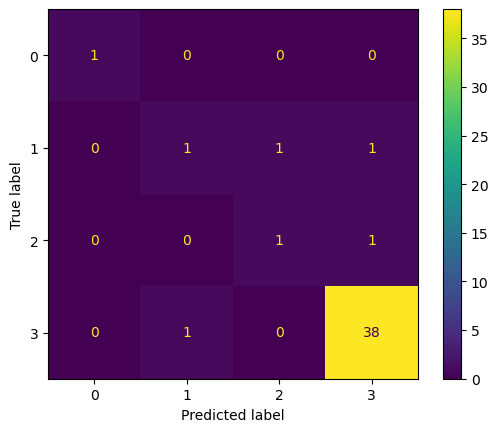

Accuracy: 0.9111111111111111
F1 macro: 0.7155063291139241
F1 micro: 0.9111111111111111
F1 weighted: 0.9048663853727146
Detailed report:
              precision    recall  f1-score   support

  B-CARDINAL       1.00      1.00      1.00         1
    B-PERSON       0.50      0.33      0.40         3
    I-PERSON       0.50      0.50      0.50         2
           O       0.95      0.97      0.96        39

    accuracy                           0.91        45
   macro avg       0.74      0.70      0.72        45
weighted avg       0.90      0.91      0.90        45



In [39]:
# Manually perform Named Entity Recognition and BIO sequence modelling on the text_03 variable
manual_03 = ['It', 'O', 'was', 'O', 'then', 'O', 'the', 'B-PERSON', 'Doctor', 'I-PERSON', 'understood-', 'O', 'the', 'O', 'small', 'O', 'part', 'O', 'of', 'O', 'his', 'O', 'brain', 'O', 'not', 'O', 'occupied', 'O', 'with', 'O', 'kissing', 'O', 'Rose', 'B-PERSON', 'calculated', 'O', 'what', 'O', 'the', 'O', 'Bad', 'B-PERSON', 'Wolf', 'I-PERSON', 'had', 'O', 'already', 'O', 'known', 'O', '.', 'O', 'The', 'O', 'vortex', 'O', 'energy', 'O', 'was', 'O', 'bonding', 'O', 'with', 'O', 'the', 'O', 'regenerative', 'O', 'energy', 'O', ',', 'O', 'and', 'O', 'dividing', 'O', 'both', 'O', 'between', 'O', 'the', 'O', 'two', 'B-CARDINAL', 'of', 'O', 'them', 'O', '.', 'O']

# Run the keep_only_bio(specific_list) function
y_true_03 = keep_only_bio(manual_03)
y_pred_03 = keep_only_bio(spacy_03)

print(y_true_03)
print(y_pred_03)

# Run the performance_measure(y_true, y_pred) function
performance_measure(y_true_03, y_pred_03)

In [40]:
# Assign the sentence to perform NER and BIO sequence modelling on to the text_04 variable
text_04 = "The TARDIS wasn't meant to translate Gallifreyan to other languages. So, very early on, The Doctor had adjusted some things so she could translate Gallifreyan to English."
# Run the NER_BIO_sequence_model(text) function
spacy_04 = NER_BIO_sequence_model(text_04)
print(spacy_04)

['The', 'O', 'TARDIS', 'B-ORG', 'was', 'O', "n't", 'O', 'meant', 'O', 'to', 'O', 'translate', 'O', 'Gallifreyan', 'B-PERSON', 'to', 'O', 'other', 'O', 'languages', 'O', '.', 'O', 'So', 'O', ',', 'O', 'very', 'O', 'early', 'O', 'on', 'O', ',', 'O', 'The', 'O', 'Doctor', 'O', 'had', 'O', 'adjusted', 'O', 'some', 'O', 'things', 'O', 'so', 'O', 'she', 'O', 'could', 'O', 'translate', 'O', 'Gallifreyan', 'B-PRODUCT', 'to', 'O', 'English', 'B-LANGUAGE', '.', 'O']


['B-PRODUCT', 'I-PRODUCT', 'O', 'O', 'O', 'O', 'O', 'B-LANGUAGE', 'O', 'O', 'O', 'O', 'O', 'O', 'B-DATE', 'I-DATE', 'I-DATE', 'O', 'B-PERSON', 'I-PERSON', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-LANGUAGE', 'O', 'B-LANGUAGE', 'O']
['O', 'B-ORG', 'O', 'O', 'O', 'O', 'O', 'B-PERSON', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-PRODUCT', 'O', 'B-LANGUAGE', 'O']


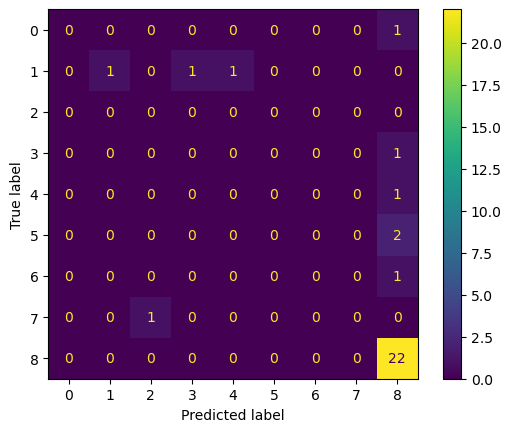

Accuracy: 0.71875
F1 macro: 0.15333333333333332
F1 micro: 0.71875
F1 weighted: 0.651875
Detailed report:
              precision    recall  f1-score   support

      B-DATE       0.00      0.00      0.00         1
  B-LANGUAGE       1.00      0.33      0.50         3
       B-ORG       0.00      0.00      0.00         0
    B-PERSON       0.00      0.00      0.00         1
   B-PRODUCT       0.00      0.00      0.00         1
      I-DATE       0.00      0.00      0.00         2
    I-PERSON       0.00      0.00      0.00         1
   I-PRODUCT       0.00      0.00      0.00         1
           O       0.79      1.00      0.88        22

    accuracy                           0.72        32
   macro avg       0.20      0.15      0.15        32
weighted avg       0.63      0.72      0.65        32



In [41]:
# Manually perform Named Entity Recognition and BIO sequence modelling on the text_04 variable
manual_04 = ['The', 'B-PRODUCT', 'TARDIS', 'I-PRODUCT', 'was', 'O', "n't", 'O', 'meant', 'O', 'to', 'O', 'translate', 'O', 'Gallifreyan', 'B-LANGUAGE', 'to', 'O', 'other', 'O', 'languages', 'O', '.', 'O', 'So', 'O', ',', 'O', 'very', 'B-DATE', 'early', 'I-DATE', 'on', 'I-DATE', ',', 'O', 'The', 'B-PERSON', 'Doctor', 'I-PERSON', 'had', 'O', 'adjusted', 'O', 'some', 'O', 'things', 'O', 'so', 'O', 'she', 'O', 'could', 'O', 'translate', 'O', 'Gallifreyan', 'B-LANGUAGE', 'to', 'O', 'English', 'B-LANGUAGE', '.', 'O']

# Run the keep_only_bio(specific_list) function
y_true_04 = keep_only_bio(manual_04)
y_pred_04 = keep_only_bio(spacy_04)

print(y_true_04)
print(y_pred_04)

# Run the performance_measure(y_true, y_pred) function
performance_measure(y_true_04, y_pred_04)

In [42]:
# Assign the sentence to perform NER and BIO sequence modelling on to the text_05 variable
text_05 = "His face looked humanoid, if it wasn't for the fact that he had a third eye right in the middle of his forehead, and his skin color wasn't exactly among the most common, but a mixture between dirt orange and yellowish. You met his kind with the Doctor a few months back. "
# Run the NER_BIO_sequence_model(text) function
spacy_05 = NER_BIO_sequence_model(text_05)
print(spacy_05)

['His', 'O', 'face', 'O', 'looked', 'O', 'humanoid', 'O', ',', 'O', 'if', 'O', 'it', 'O', 'was', 'O', "n't", 'O', 'for', 'O', 'the', 'O', 'fact', 'O', 'that', 'O', 'he', 'O', 'had', 'O', 'a', 'O', 'third', 'B-ORDINAL', 'eye', 'O', 'right', 'O', 'in', 'O', 'the', 'O', 'middle', 'O', 'of', 'O', 'his', 'O', 'forehead', 'O', ',', 'O', 'and', 'O', 'his', 'O', 'skin', 'O', 'color', 'O', 'was', 'O', "n't", 'O', 'exactly', 'O', 'among', 'O', 'the', 'O', 'most', 'O', 'common', 'O', ',', 'O', 'but', 'O', 'a', 'O', 'mixture', 'O', 'between', 'O', 'dirt', 'O', 'orange', 'O', 'and', 'O', 'yellowish', 'O', '.', 'O', 'You', 'O', 'met', 'O', 'his', 'O', 'kind', 'O', 'with', 'O', 'the', 'O', 'Doctor', 'O', 'a', 'B-DATE', 'few', 'I-DATE', 'months', 'I-DATE', 'back', 'I-DATE', '.', 'O']


['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-CARDINAL', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-PERSON', 'B-PERSON', 'B-DATE', 'I-DATE', 'I-DATE', 'I-DATE', 'O']
['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-ORDINAL', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-DATE', 'I-DATE', 'I-DATE', 'I-DATE', 'O']


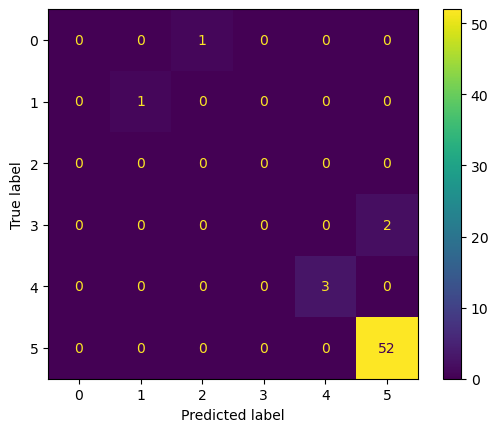

Accuracy: 0.9491525423728814
F1 macro: 0.49685534591194963
F1 micro: 0.9491525423728814
F1 weighted: 0.9325231851614967
Detailed report:
              precision    recall  f1-score   support

  B-CARDINAL       0.00      0.00      0.00         1
      B-DATE       1.00      1.00      1.00         1
   B-ORDINAL       0.00      0.00      0.00         0
    B-PERSON       0.00      0.00      0.00         2
      I-DATE       1.00      1.00      1.00         3
           O       0.96      1.00      0.98        52

    accuracy                           0.95        59
   macro avg       0.49      0.50      0.50        59
weighted avg       0.92      0.95      0.93        59



In [43]:
# Manually perform Named Entity Recognition and BIO sequence modelling on the text_05 variable
manual_05 = ['His', 'O', 'face', 'O', 'looked', 'O', 'humanoid', 'O', ',', 'O', 'if', 'O', 'it', 'O', 'was', 'O', "n't", 'O', 'for', 'O', 'the', 'O', 'fact', 'O', 'that', 'O', 'he', 'O', 'had', 'O', 'a', 'O', 'third', 'B-CARDINAL', 'eye', 'O', 'right', 'O', 'in', 'O', 'the', 'O', 'middle', 'O', 'of', 'O', 'his', 'O', 'forehead', 'O', ',', 'O', 'and', 'O', 'his', 'O', 'skin', 'O', 'color', 'O', 'was', 'O', "n't", 'O', 'exactly', 'O', 'among', 'O', 'the', 'O', 'most', 'O', 'common', 'O', ',', 'O', 'but', 'O', 'a', 'O', 'mixture', 'O', 'between', 'O', 'dirt', 'O', 'orange', 'O', 'and', 'O', 'yellowish', 'O', '.', 'O', 'You', 'O', 'met', 'O', 'his', 'O', 'kind', 'O', 'with', 'O', 'the', 'B-PERSON', 'Doctor', 'B-PERSON', 'a', 'B-DATE', 'few', 'I-DATE', 'months', 'I-DATE', 'back', 'I-DATE', '.', 'O']

# Run the keep_only_bio(specific_list) function
y_true_05 = keep_only_bio(manual_05)
y_pred_05 = keep_only_bio(spacy_05)

print(y_true_05)
print(y_pred_05)

# Run the performance_measure(y_true, y_pred) function
performance_measure(y_true_05, y_pred_05)